# SuperStore Sales  Dataset :
**Domain: Retail**

# Objective Of Project:
**"Perform a thorough Exploratory Data Analysis on Retail Sales dataset to uncover patterns, customer behaviour trends and actionable business insights"**

# Feature Checklist :

* Load dataset and perform initial inspection : shape, column dtypes, null values check 

* Descriptive Statistics : mean, median, mode, standard deviation for all numerical columns

* Time series analysis : plot monthly and quarterly sales trends line charts

* Customer demographics analysis : Distribution of customer age groups, gender breakdown

* Product analysis top 10 best-selling products : revenue by product category (Bar Chart)

* Heatmap : Correlation matrix between numerical variables

* Conclusion section

# Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

#  Load dataset and perform initial inspection : 
**shape, column dtypes, null values check**

In [23]:
df = pd.read_csv("Sample - Superstore.csv",encoding="cp1252")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# Define for Columns & Rows
df.shape

(9994, 21)

* Total Records : 9994
* Total Columns : 21

In [4]:
# Check Duplicate Values
df.duplicated().sum()

np.int64(0)

In [5]:
# Check Any Variable Contain Unique Values 
df.nunique()

Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

In [6]:
# All Categorical Objective Columns
df.select_dtypes(include="object").columns

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region',
       'Product ID', 'Category', 'Sub-Category', 'Product Name'],
      dtype='str')

In [7]:
# All Numerical Columns
df.select_dtypes(include="number").columns

Index(['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit'], dtype='str')

In [8]:
# Checking Null Values
df.isnull().sum()[df.isnull().sum()>0]

Series([], dtype: int64)

# Descriptive Statistics : 
**mean, median, mode, standard deviation for all numerical columns**

In [9]:
# Descriptive Statistics : Mean, Median, Mode, Standard Deviation for all Numerical Columns
num = df.select_dtypes("number").drop(columns=["Row ID", "Postal Code"])
stats = num.agg(["mean", "median", "std"]).T
stats["mode"] = num.mode().iloc[0]
stats.round(2)

,mean,median,std,mode
Sales,229.86,54.49,623.25,12.96
Quantity,3.79,3.00,2.23,3.00
Discount,0.16,0.20,0.21,0.00
Profit,28.66,8.67,234.26,0.00


In [10]:
# Information : Columns, Null-Not NUll values, Dtype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

# Exploratory Data Analysis (EDA) 

# Time series analysis : 
**plot monthly and quarterly sales trends line charts**

In [11]:
# COlumn : 'Order Date' Convert into Date Time
df["Order Date"] = pd.to_datetime(df['Order Date'],format="%m/%d/%Y")
df = df.set_index("Order Date").sort_index()

monthly = df["Sales"].resample("MS").sum()
quarterly = df["Sales"].resample("QS").sum()

In [12]:
print("Monthly Sales:\n",monthly.head(), "\n")
print("Quarterly Sales:\n",quarterly.head())

Monthly Sales:
 Order Date
2014-01-01    14236.895
2014-02-01     4519.892
2014-03-01    55691.009
2014-04-01    28295.345
2014-05-01    23648.287
Freq: MS, Name: Sales, dtype: float64 

Quarterly Sales:
 Order Date
2014-01-01     74447.7960
2014-04-01     86538.7596
2014-07-01    143633.2123
2014-10-01    179627.7302
2015-01-01     68851.7386
Freq: QS-JAN, Name: Sales, dtype: float64


# Line Chart :
**Monthly Sales Trends**

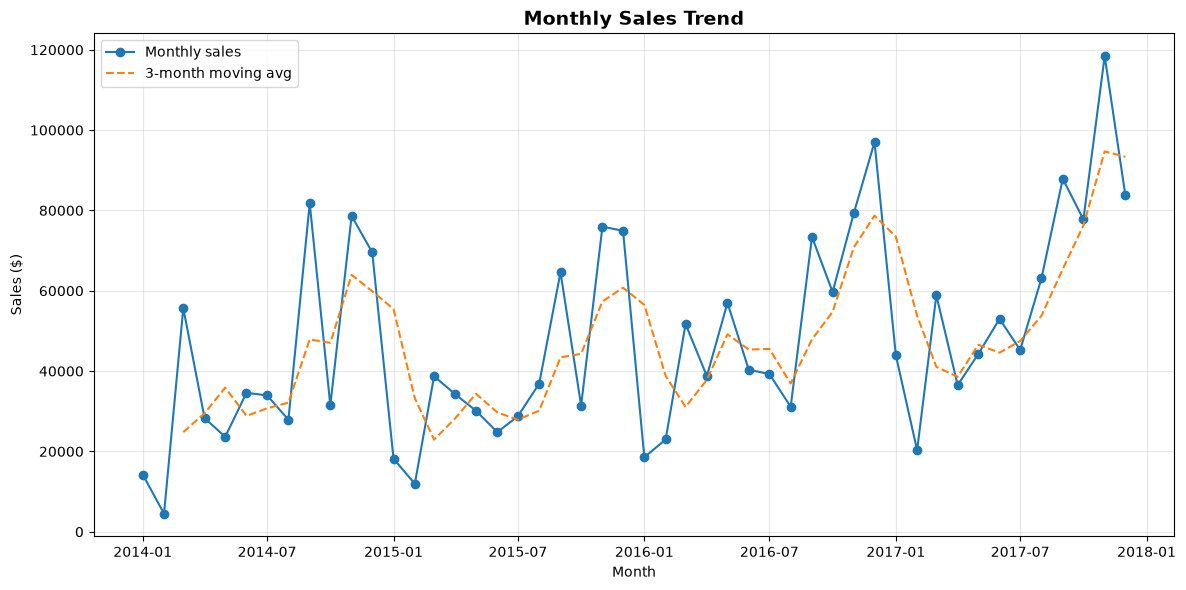

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(monthly.index, monthly.values, marker="o", color="#1f77b4", label="Monthly sales")
plt.plot(monthly.index, monthly.rolling(3).mean(), "--", color="#ff7f0e", label="3-month moving avg")
plt.title("Monthly Sales Trend", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("monthly_sales_trend.png", dpi=150)
plt.show()

# Explanation :
**Monthly Sales Trend**

* Upward trend: Sales are growing overall. The yearly peaks rise from about 80k in 2014 and 76k in 2015 to 97k in 2016 and 118k in 2017.

* Seasonality: The pattern repeats every year. Sales are low in January and February (as low as 5k–20k) and peak in September to December, the holiday season.

* High volatility: Sales swing a lot from month to month, which is why the blue line is jagged.

* Moving average: The orange dashed line smooths the noise and confirms the upward trend, especially from 2016 onward.

* Latest data: Sales were strong at the end of 2017, with a peak of about 118k in November and a drop to about 84k in December.

**Quarterly Sales Trend**

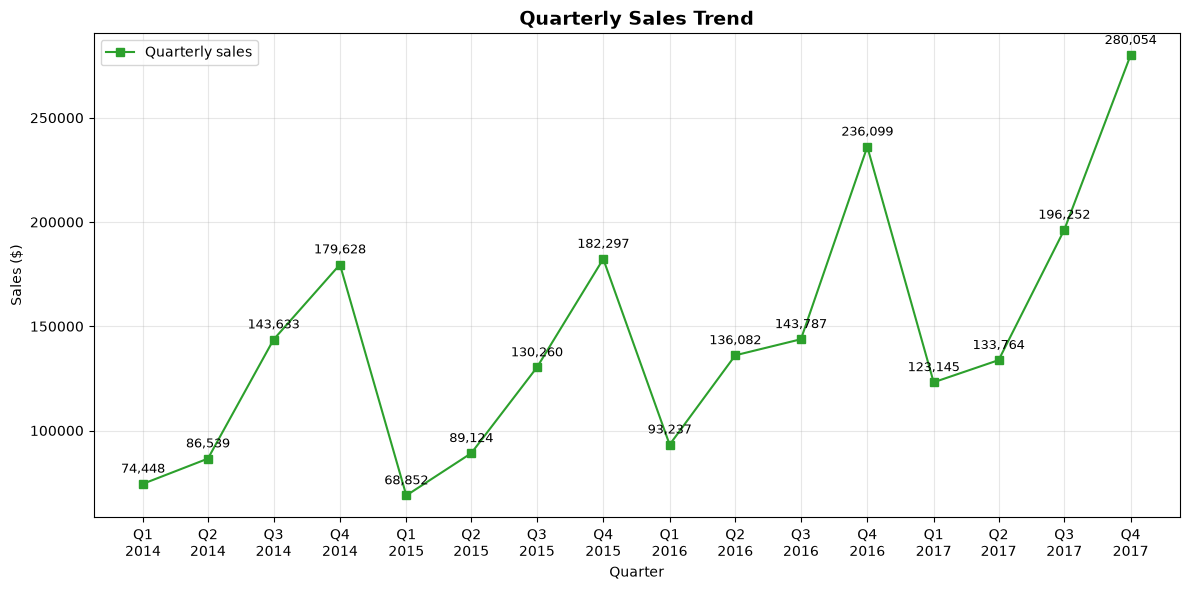

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(quarterly.index, quarterly.values, marker="s", color="#2ca02c", label="Quarterly sales")
plt.xticks(quarterly.index, [f"Q{d.quarter}\n{d.year}" for d in quarterly.index])
for x, y in zip(quarterly.index, quarterly.values):
    plt.annotate(f"{y:,.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.title("Quarterly Sales Trend", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales ($)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("quarterly_sales_trend.png", dpi=150)
plt.show()

# Explanation :
**Quarterly Sales Trend**
* Strong seasonality: Every year follows the same pattern. Sales are lowest in Q1, rise through Q2 and Q3, and peak in Q4 (the holiday season).

* Q4 peaks keep growing: 179k (2014) → 182k (2015) → 236k (2016) → 280k (2017).

* Q1 is the weakest quarter each year: It drops sharply after every Q4, to about 69k–93k in 2014–2016.

* Growth is clear in 2017: Q1 2017 (123k) is much higher than Q1 2016 (93k). Q3 and Q4 2017 are also the best of their kind so far.

* 2015 was flat: Q4 2015 (182k) was barely above Q4 2014 (180k), so growth only picked up in 2016 and 2017.

# Customer demographics analysis :
**Distribution of customer age groups, gender breakdown**
**Note:** The dataset has no age or gender columns, so a true age/gender breakdown is not possible. Customers are grouped by spending behaviour instead.

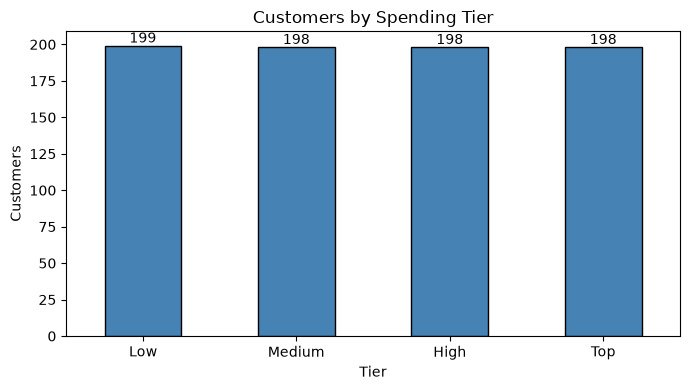

spend_tier
Low       0.055039
Medium    0.144387
High      0.250920
Top       0.549654
Name: total_sales, dtype: float64


In [15]:
cust = df.groupby("Customer ID").agg(total_sales=("Sales", "sum"),
                                     orders=("Order ID", "nunique"))
cust["spend_tier"] = pd.qcut(cust["total_sales"], 4,
                             labels=["Low", "Medium", "High", "Top"])
ax = cust["spend_tier"].value_counts().sort_index().plot(
    kind="bar", color="steelblue", edgecolor="black", figsize=(7, 4))
ax.bar_label(ax.containers[0])
plt.title("Customers by Spending Tier"); plt.xlabel("Tier"); plt.ylabel("Customers")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# Share of total sales from the top tier
print(cust.groupby("spend_tier", observed=True)["total_sales"].sum() / cust["total_sales"].sum())

## Customers by Spending Tier

**Key findings:**
- Customers are split into four equal groups (Low, Medium, High, Top) by total spend.
- The **Top 25% of customers bring in about 55% of all sales**.
- The **Low 25% bring in only about 5.5%**.

**Insight:**
A small group of high-spending customers drives most of the revenue. Keeping them happy with loyalty rewards or special offers matters more than chasing many small buyers.

# Product Analysis :

**Top 10 Best-Selling Products**

Top 10 products by revenue:
 Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.58
GBC DocuBind TL300 Electric Binding System                                     19823.48
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.90
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64 



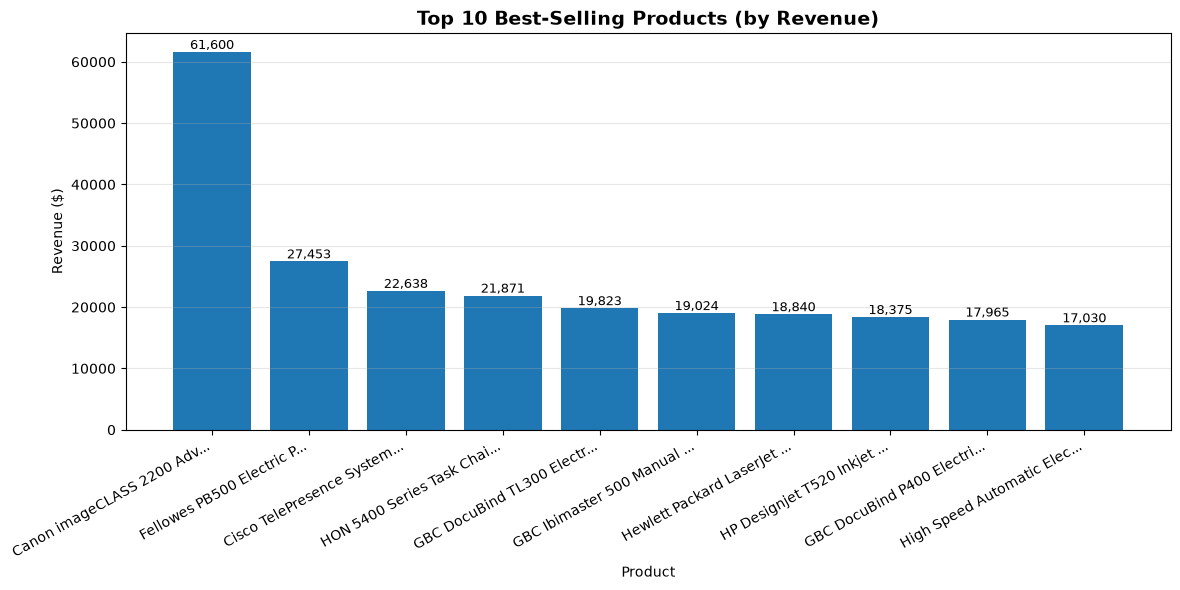

In [16]:
def short(name, n=25):
    return name if len(name) <= n else name[:n] + "..."

top_products = (
    df.groupby("Product Name")["Sales"].sum()
      .sort_values(ascending=False)
      .head(10)
      .round(2)
)
print("Top 10 products by revenue:\n", top_products, "\n")

plt.figure(figsize=(12, 6))
bars = plt.bar([short(p) for p in top_products.index], top_products.values, color="#1f77b4")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f"{bar.get_height():,.0f}", ha="center", va="bottom", fontsize=9)
plt.title("Top 10 Best-Selling Products (by Revenue)", fontsize=14, fontweight="bold")
plt.xlabel("Product")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=29, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("top10_products.png", dpi=150)
plt.show()

# Explanation :
## Top 10 Best-Selling Products (by Revenue)

**What this chart shows:**
This bar chart shows the 10 products that earned the most revenue.

**Key findings:**
- **Canon imageCLASS 2200 Advanced Copier** is the top product, with about **$61.6K** in revenue.
- It earns more than **double** the second product (Fellowes PB500 Binding Machine, about **$27.5K**).
- The remaining products earn between about **$17K and $23K** each, so the gaps between them are small.
- Most of the top 10 are office machines (copier, binding machines, printers, videoconferencing unit), plus one chair.

**Insight:**
The business relies on a few high-priced items for a big part of its revenue. These products should always be in stock and are good candidates for promotions or bundle deals.

# Revenue by Product Category :

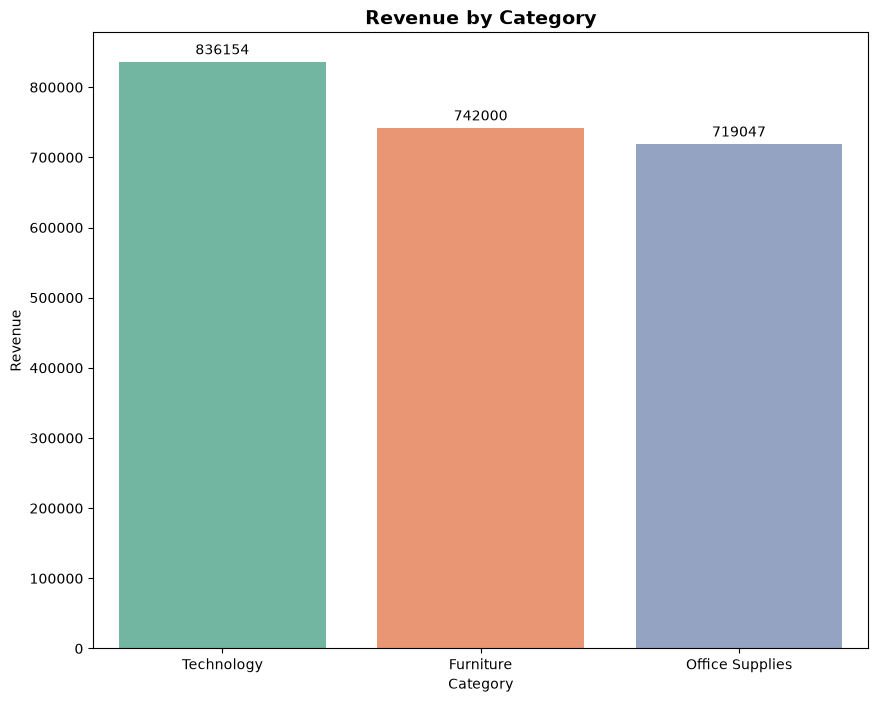

In [17]:
cat_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10,8))
ax = sns.barplot(data=cat_sales, x='Category', y='Sales',
            hue='Category', palette='Set2', legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=3)
    
plt.title("Revenue by Category", fontsize=14, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.show()

# Explanation :
## Revenue by Category

**What this chart shows:**
This bar chart compares total revenue across the three product categories.

**Key findings:**
- **Technology** earns the most, about **$836K** (36.4%).
- **Furniture** is second, about **$742K** (32.3%).
- **Office Supplies** is the lowest, about **$719K** (31.3%).


**Insight:**
Revenue is well balanced, so the business does not depend on one category. Technology is the best place to focus promotions.

# Pie Chart :
**Sales Share by Category**

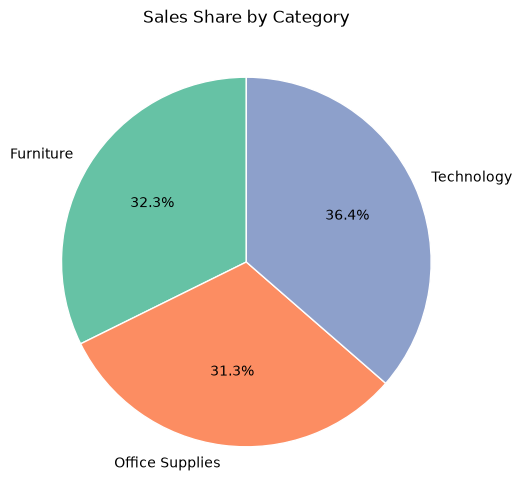

In [18]:
cat = df.groupby('Category')['Sales'].sum()
plt.figure(figsize=(6, 6))
plt.pie(cat, labels=cat.index, autopct='%1.1f%%', startangle=90,
        colors=sns.color_palette('Set2'), wedgeprops={'edgecolor': 'white'})
plt.title("Sales Share by Category")
plt.show()

# Explanation :
The pie shows the same data as the bar chart, as percentage shares: Technology 36.4%, Furniture 32.3%, Office Supplies 31.3%.

# Heatmap :
**Correlation matrix between Numerical Variables**

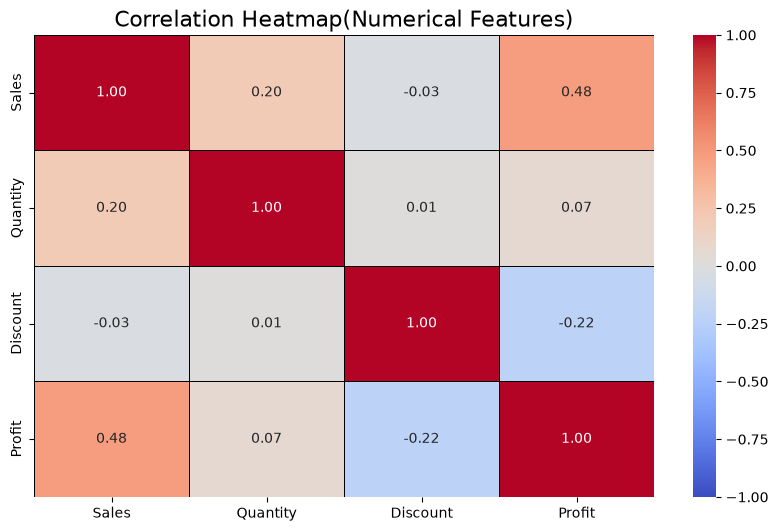

In [19]:
plt.figure(figsize=(10, 6))
sns.heatmap(data=df[["Sales","Quantity","Discount","Profit"]].corr(),
            annot=True, fmt=".2f",
            cmap='coolwarm', vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor='black')
plt.title("Correlation Heatmap(Numerical Features)", fontsize=16)
plt.show()

# Explanation :
## Correlation Heatmap

- **Sales and Profit (0.48):** moderate positive relationship. Bigger sales usually bring more profit, but not always.
- **Quantity and Sales (0.20):** weak positive relationship. Buying more raises sales a little, but the product price matters more.
- **Discount and Profit (negative):** higher discounts tend to lower profit.

**Insight:** No pair of variables is strongly correlated, so no single factor explains profit. Discount is the one worth watching.

# Average Profit/Order by Discount Level
**Non-Obvious insight**

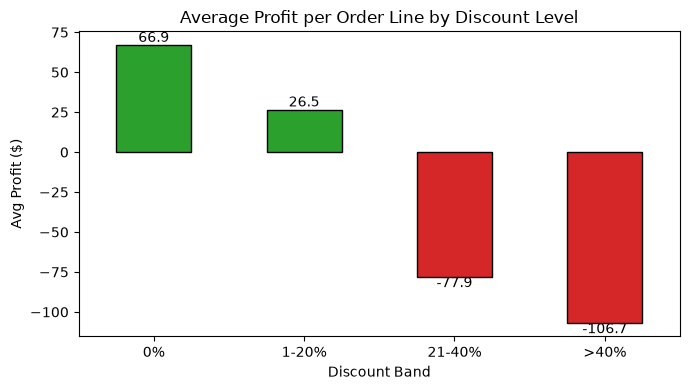

In [20]:
df["Discount Band"] = pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1],
                             labels=["0%", "1-20%", "21-40%", ">40%"])
avg = df.groupby("Discount Band", observed=True)["Profit"].mean()

ax = avg.plot(kind="bar", color=["#2ca02c" if v > 0 else "#d62728" for v in avg],
              edgecolor="black", figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.title("Average Profit per Order Line by Discount Level")
plt.ylabel("Avg Profit ($)"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# Explanation :
## Average Profit by Discount Level

**What this chart shows:**
The average profit per order line at different discount levels.

**Key findings:**
- Orders with **no discount or a small discount (up to 20%)** make a **profit**.
- Orders with **discounts above 20%** make a **loss on average**.
- The higher the discount, the bigger the loss.

**Insight:**
Heavy discounts look like they increase sales, but they destroy profit. This is the non-obvious finding: more sales are not always good for the business.

# Bar plot :
**Revenue by Region**

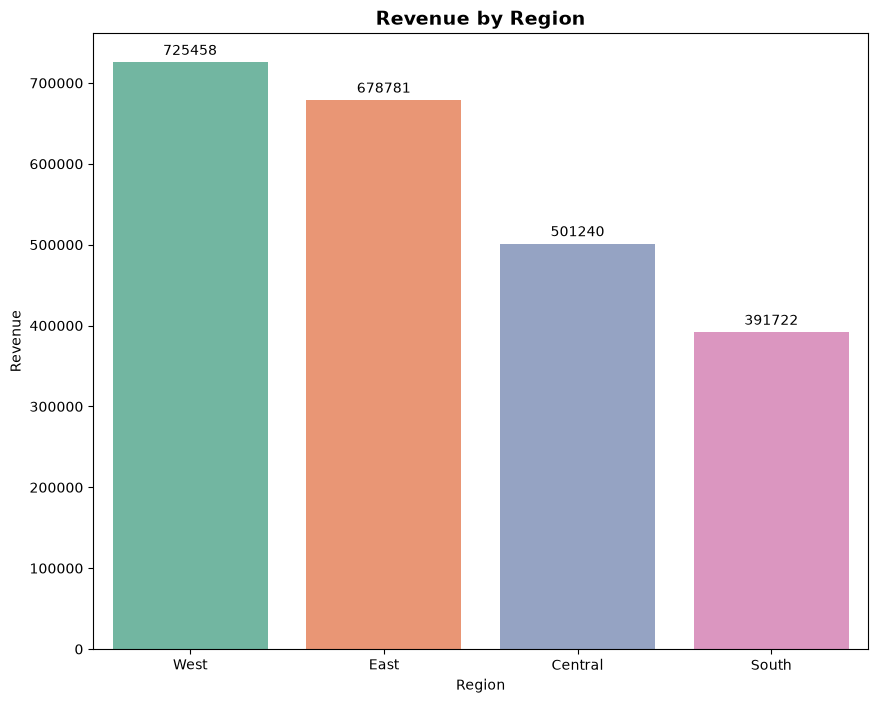

In [21]:
cat_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10,8))
ax = sns.barplot(data=cat_sales, x='Region', y='Sales',
            hue='Region', palette='Set2', legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=3)
    
plt.title("Revenue by Region", fontsize=14, fontweight="bold")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

# Explanation :
## Revenue by Region

**What this chart shows:**
This bar chart compares total revenue across the four regions: West, East, Central, and South.

**Key findings:**
- **West** is the top region, with about **$725K** in revenue (around 31% of the total).
- **East** is a close second, with about **$679K** (around 29%).
- **Central** comes third, with about **$501K** (around 22%).
- **South** is the lowest, with about **$392K** (around 17%).

**Insight:**
West and East together bring in about 60% of total revenue, so they are the strongest markets. South has the most room to grow and could use more marketing or promotions.

**Revenue by Segment**

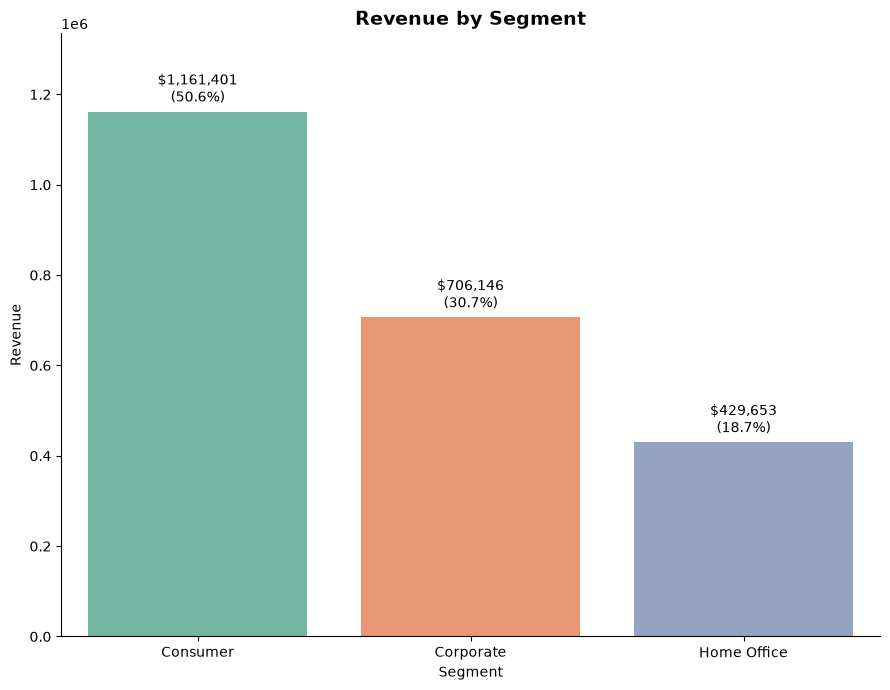

In [22]:

seg = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False).reset_index()
total = seg["Sales"].sum()

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=seg, x="Segment", y="Sales", hue="Segment", palette="Set2", legend=False, ax=ax)

# Labels: $ value + % share
for bar, val in zip(ax.patches, seg["Sales"]):
    ax.annotate(f"${val:,.0f}\n({val/total:.1%})",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 4),
                textcoords="offset points")

# Y-axis in millions, no 1e6 offset

ax.set_ylim(0, seg["Sales"].max() * 1.15)   # headroom for labels

ax.set_title("Revenue by Segment", fontsize=14, fontweight="bold")
ax.set_xlabel("Segment")
ax.set_ylabel("Revenue")
sns.despine()
plt.tight_layout()
plt.show()

# Explanation :
## Revenue by Segment

**What this chart shows:**
This bar chart compares total Revenue across the three customer segments: Consumer, Corporate, and Home Office.

**Key findings:**
- **Consumer** is the top segment, with about **$1.16M** in Revenue (around 51% of the total).
- **Corporate** comes second, with about **$706K** (around 31%).
- **Home Office** is the smallest, with about **$430K** (around 19%).

**In simple words:**
Regular consumers bring in about half of all Revenue. Corporate customers bring in about one-third, and home office customers bring in the least.

**Insight:**
The business depends most on the Consumer segment, so it is the main revenue driver. Corporate and Home Office have room to grow, for example through targeted offers or business deals.


# Conclusion :

## Key Insight
- **Sales are growing, with strong seasonality.** Q4 peaks rose every year (179K → 182K → 236K → 280K), and Q1 is the weakest quarter each year.
- **Consumer is the main revenue driver** (about 51% of sales), followed by Corporate (31%) and Home Office (19%).
- **West and East lead by region** (about $725K and $679K), while Central ($501K) and South ($392K) lag.
- **Category revenue is balanced.** Technology leads slightly (36.4%), then Furniture (32.3%) and Office Supplies (31.3%).
- **Revenue depends on a few big items and customers.** The Canon copier earns more than double the next product, and the top 25% of customers bring in about 55% of sales.
- **Customer age and gender could not be analysed** because the dataset has no such columns.

## Recommendations
1. **Plan around seasonality.** Build stock and marketing for September to December, and run promotions in Q1 to lift the weakest quarter.
2. **Grow the South and Central regions** with local campaigns and offers to close the gap with West and East.
3. **Reward top customers.** Use loyalty programs and early access offers to keep the top 25% of customers, who bring in over half of sales.
4. **Expand Corporate and Home Office** with bulk-order deals to reduce dependence on Consumer.